# 01 · EDA & Business Insights — MoMo e-wallet reviews on Google Play

**Business questions**
1. How does user satisfaction evolve over time and across app versions?
2. Which releases made the experience worse (early-warning signal)?
3. How quickly and how often does MoMo respond to users?
4. What is unusual about the rating distribution (polarisation, spam) that matters when ratings are used as ML labels?

Data: every public review, crawled with `google-play-scraper` (`src/momo_reviews/crawl.py`) and cleaned by `src/momo_reviews/preprocess.py`. User names and avatars are never stored. Review text is in Vietnamese.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} reviews | {df['at'].min():%Y-%m-%d} → {df['at'].max():%Y-%m-%d}")

217,357 reviews | 2014-05-28 → 2026-10-23


## 1. Data overview & KPIs

In [2]:
kpi = pd.Series({
    "Reviews": f"{len(df):,}",
    "Average rating": f"{df['score'].mean():.2f} ★",
    "% negative (1–2★)": f"{(df['sentiment']=='negative').mean():.1%}",
    "% positive (4–5★)": f"{(df['sentiment']=='positive').mean():.1%}",
    "% with text": f"{(df['n_words']>0).mean():.1%}",
    "% replied by MoMo": f"{df['has_reply'].mean():.1%}",
    "% promotional spam": f"{df['is_spam'].mean():.2%}",
    "% missing appVersion": f"{df['version'].isna().mean():.1%}",
}, name="Value")
kpi.to_frame()

,Value
Reviews,"217,357"
Average rating,3.37 ★
% negative (1–2★),38.3%
% positive (4–5★),57.5%
% with text,99.9%
% replied by MoMo,16.3%
% promotional spam,0.10%
% missing appVersion,23.2%


In [3]:
missing = df[["content", "version", "replyContent", "thumbsUpCount"]].isna().mean().rename("missing rate")
missing.to_frame().style.format("{:.1%}")

,missing rate
content,0.0%
version,23.2%
replyContent,83.7%
thumbsUpCount,0.0%


## 2. Rating distribution — a polarised "J-shape"

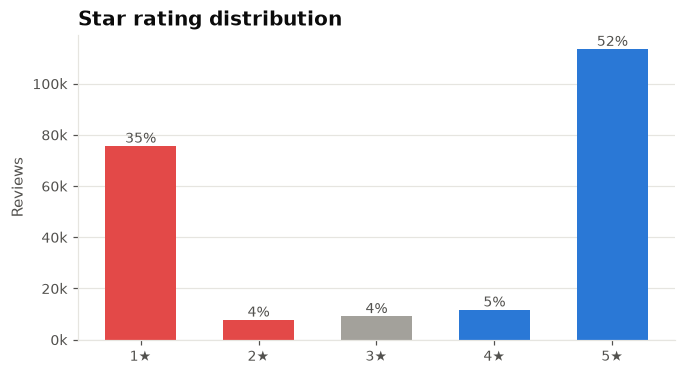

In [4]:
dist = df["score"].value_counts().sort_index()
colors = [SENTIMENT_COLORS[s] for s in ["negative", "negative", "neutral", "positive", "positive"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(dist.index.astype(str) + "★", dist.values, color=colors, width=0.6)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v/dist.sum():.0%}", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_title("Star rating distribution"); ax.set_ylabel("Reviews")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.grid(axis="x", visible=False)
save(fig, "01_rating_distribution"); plt.show()

**Takeaway.** Ratings are strongly polarised: lots of 5★ and 1★, very few 2–3★ — typical for app reviews (people write when they are delighted or furious).
Implication for ML: the *neutral* class is rare → use **macro-F1** instead of accuracy and balance class weights.

## 3. Trends over time

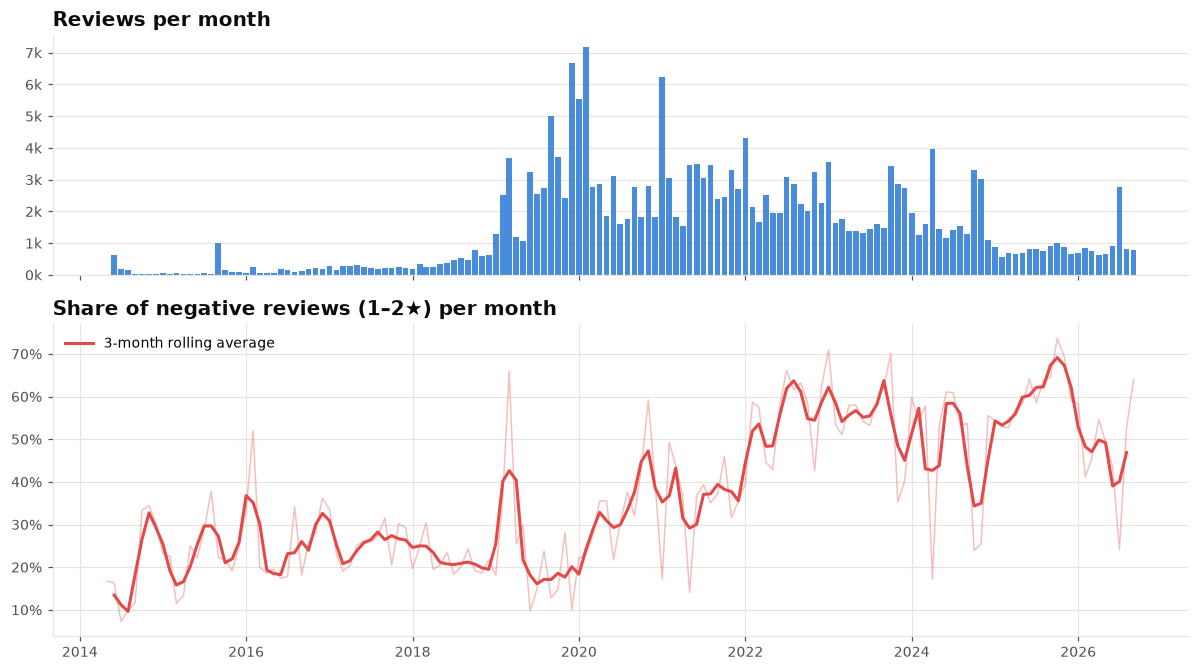

In [5]:
monthly = df.groupby("month").agg(n=("reviewId", "size"), avg=("score", "mean"), neg=("sentiment", lambda s: (s == "negative").mean()))
monthly = monthly[monthly.index < monthly.index.max()]  # drop the current, incomplete month

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].bar(monthly.index, monthly["n"], width=25, color=BLUE, alpha=0.85)
axes[0].set_title("Reviews per month"); axes[0].grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

axes[1].plot(monthly.index, monthly["neg"], color=SENTIMENT_COLORS["negative"], alpha=0.35, linewidth=1)
axes[1].plot(monthly.index, monthly["neg"].rolling(3, center=True).mean(),
             color=SENTIMENT_COLORS["negative"], label="3-month rolling average")
axes[1].set_title("Share of negative reviews (1–2★) per month")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].legend(loc="upper left")
fig.tight_layout(); save(fig, "01_monthly_trend"); plt.show()

In [6]:
yearly = df.groupby("year").agg(reviews=("reviewId", "size"), avg_rating=("score", "mean"),
                                negative_share=("sentiment", lambda s: (s == "negative").mean()),
                                reply_rate=("has_reply", "mean"))
yearly["yoy_growth"] = yearly["reviews"].pct_change()
yearly.style.format({"reviews": "{:,}", "avg_rating": "{:.2f}", "negative_share": "{:.1%}",
                     "reply_rate": "{:.1%}", "yoy_growth": "{:+.0%}"}, na_rep="—") \
      .background_gradient(subset=["negative_share"], cmap="Reds")

,reviews,avg_rating,negative_share,reply_rate,yoy_growth
year,,,,,
2014,"1,089",4.14,14.9%,72.8%,—
2015,"1,623",3.84,22.3%,76.6%,+49%
2016,"1,559",3.57,29.3%,90.4%,-4%
2017,"2,759",3.74,26.0%,1.1%,+77%
2018,"5,120",3.98,21.3%,0.2%,+86%
2019,"36,043",4.00,22.4%,3.5%,+604%
2020,"35,842",3.64,31.1%,20.6%,-1%
2021,"36,880",3.58,32.9%,3.4%,+3%
2022,"30,203",2.77,53.5%,4.3%,-18%


In [7]:
roll = monthly["neg"].rolling(12, min_periods=6)
spikes = monthly.assign(z=(monthly["neg"] - roll.mean().shift(1)) / roll.std().shift(1))
display(Markdown("**Months where the negative share spiked (z-score vs. the previous 12 months > 2):**"))
spikes[spikes["z"] > 2][["n", "avg", "neg", "z"]].sort_values("z", ascending=False).head(10) \
    .style.format({"n": "{:,}", "avg": "{:.2f}", "neg": "{:.1%}", "z": "{:.1f}"})

**Months where the negative share spiked (z-score vs. the previous 12 months > 2):**

,n,avg,neg,z
month,,,,
2019-03-01 00:00:00,"3,687",2.32,66.0%,7.8
2019-02-01 00:00:00,"2,514",3.46,36.4%,4.1
2016-02-01 00:00:00,250,2.78,52.0%,3.8
2020-11-01 00:00:00,"2,789",2.50,59.1%,3.4
2022-02-01 00:00:00,"2,130",2.57,58.6%,2.5
2022-07-01 00:00:00,"3,077",2.27,66.2%,2.4
2020-04-01 00:00:00,"2,851",3.46,35.5%,2.1
2014-11-01 00:00:00,29,3.38,34.5%,2.0


**Use case.** This table is a simple **anomaly alert**: run weekly, it tells the product team as soon as an incident or release pushes complaints up — before the overall Store rating moves.

## 4. Ratings by app version

In [8]:
by_major = (df.dropna(subset=["major_version"])
              .groupby("major_version")
              .agg(n=("reviewId", "size"), rating=("score", "mean"), neg=("sentiment", lambda s: (s == "negative").mean()),
                   first_seen=("at", "min"), last_seen=("at", "max")))
by_major = by_major[by_major["n"] >= 200].sort_index(key=lambda i: i.astype(int))
by_major.style.format({"n": "{:,}", "rating": "{:.2f}", "neg": "{:.1%}",
                       "first_seen": "{:%Y-%m}", "last_seen": "{:%Y-%m}"})

,n,rating,neg,first_seen,last_seen
major_version,,,,,
1,"3,010",3.72,25.1%,2014-05,2021-09
2,"59,386",3.89,24.7%,2017-01,2026-10
3,"45,415",3.30,39.7%,2020-10,2026-10
4,"51,796",2.91,50.4%,2022-07,2026-10
5,"7,302",3.27,41.9%,2025-10,2026-10


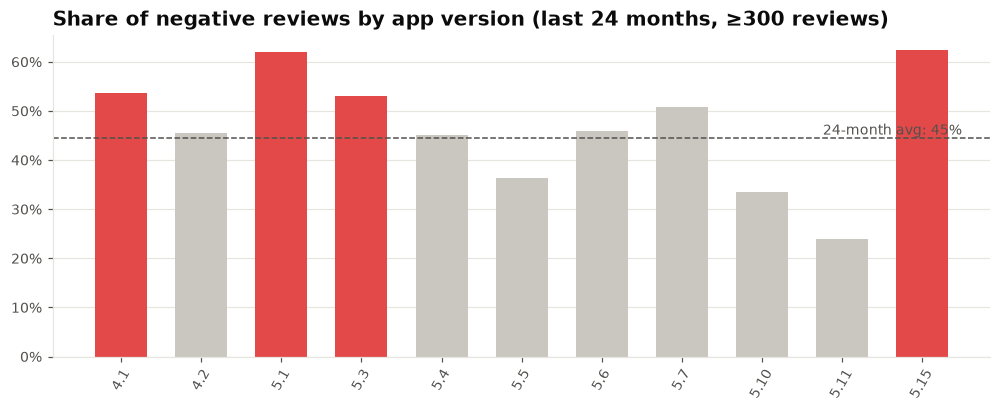

Versions in red are >15% above the average negative share — candidates for a release-notes / crash-log review.

In [9]:
recent = df[df["at"] >= df["at"].max() - pd.DateOffset(months=24)].dropna(subset=["version"])
recent = recent.assign(minor=recent["version"].str.extract(r"^(\d+\.\d+)")[0])
by_minor = recent.groupby("minor").agg(n=("reviewId", "size"), neg=("sentiment", lambda s: (s == "negative").mean()))
by_minor = by_minor[by_minor["n"] >= 300]
by_minor = by_minor.loc[sorted(by_minor.index, key=lambda v: tuple(int(x) for x in v.split(".")))]
base = (recent["sentiment"] == "negative").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
col = [SENTIMENT_COLORS["negative"] if v > base * 1.15 else "#c9c7c0" for v in by_minor["neg"]]
ax.bar(by_minor.index, by_minor["neg"], color=col, width=0.65)
ax.axhline(base, color=INK_2, linestyle="--", linewidth=1)
ax.text(len(by_minor) - 0.5, base, f" 24-month avg: {base:.0%}", va="bottom", ha="right", fontsize=9, color=INK_2)
ax.set_title("Share of negative reviews by app version (last 24 months, ≥300 reviews)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
save(fig, "01_negative_by_version"); plt.show()
display(Markdown("Versions in red are >15% above the average negative share — candidates for a release-notes / crash-log review."))

## 5. How does MoMo respond to users?

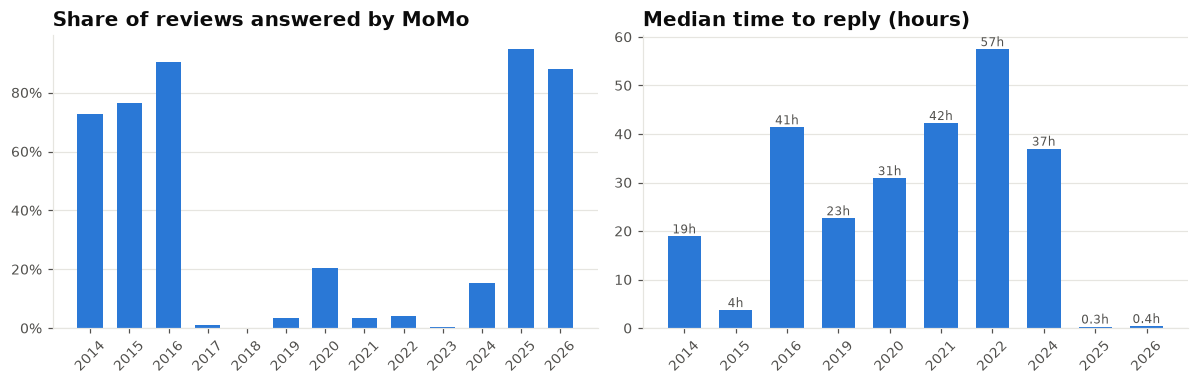

Reply rate by sentiment: negative: 24%, neutral: 21%, positive: 11%
Overall median time to reply: 18.5 hours


In [10]:
reply = df.groupby("year").agg(rate=("has_reply", "mean"), n_reply=("has_reply", "sum"))
replied = df[df["has_reply"] & (df["reply_hours"] >= 0)]
reply_time = replied.groupby("year")["reply_hours"].median()
reply_time = reply_time[reply.loc[reply_time.index, "n_reply"] >= 100]   # skip years with too few replies

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(reply.index.astype(str), reply["rate"], color=BLUE, width=0.65)
axes[0].set_title("Share of reviews answered by MoMo"); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].tick_params(axis="x", rotation=45); axes[0].grid(axis="x", visible=False)
axes[1].bar(reply_time.index.astype(str), reply_time.values, color=BLUE, width=0.65)
for x, v in zip(reply_time.index.astype(str), reply_time.values):
    axes[1].text(x, v, f"{v:.1f}h" if v < 1 else f"{v:.0f}h", ha="center", va="bottom", fontsize=8, color=INK_2)
axes[1].set_title("Median time to reply (hours)"); axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "01_reply_behaviour"); plt.show()
print("Reply rate by sentiment: " + ", ".join(f"{k}: {v:.0%}" for k, v in df.groupby("sentiment")["has_reply"].mean().items()))
print(f"Overall median time to reply: {replied['reply_hours'].median():.1f} hours")

**Takeaway.** The reply policy changed sharply: between 2017 and 2023 MoMo answered very few reviews, while from 2025 it answers ~90%+ within a median of under an hour — most likely automated or semi-automated replies. The natural next step is to measure whether replies actually *resolve* issues (e.g. users raising their rating afterwards).

## 6. Which complaints does the community agree with most?

In [11]:
helpful = df.groupby("sentiment")["thumbsUpCount"].agg(["mean", "median", lambda s: (s > 0).mean()])
helpful.columns = ["avg_thumbs_up", "median", "% with ≥1 thumbs-up"]
display(helpful.style.format({"avg_thumbs_up": "{:.2f}", "median": "{:.0f}", "% with ≥1 thumbs-up": "{:.1%}"}))
display(Markdown("**Top 8 most 'helpful'-voted negative reviews in the last 12 months** — complaints that speak for many users:"))
last12 = df[df["at"] >= df["at"].max() - pd.DateOffset(months=12)]
last12[last12.sentiment == "negative"].nlargest(8, "thumbsUpCount")[["at", "score", "thumbsUpCount", "version", "content"]]

,avg_thumbs_up,median,% with ≥1 thumbs-up
sentiment,,,
negative,2.63,0,28.8%
neutral,1.72,0,21.6%
positive,0.52,0,14.1%


**Top 8 most 'helpful'-voted negative reviews in the last 12 months** — complaints that speak for many users:

,at,score,thumbsUpCount,version,content
214502,2026-07-23 14:12:20,1,217,5.11.0,"- mỗi tháng đều hiện nhắc thông báo có chuyển tiền định kỳ cho ngân hàng nào đó không biết, không có chỗ tắt - mấy hôm nay cực kì lag, mất 10-15s mỗi lần th..."
209120,2026-02-15 15:17:41,1,176,5.5.0,chuyển khoản bị treo trừ tiền 2 ngày vẫn không giải quyết. làm riết sợ sử dụng app này luôn.
207568,2025-12-12 08:14:50,1,130,5.2.1,"app tệ, link bank thì cứ không thanh toán qua bank mà bắt nạp tiền mới cho tt. vô dụng"
207915,2025-12-31 20:33:06,1,126,5.3.0,"như quần hỗ trợ không rành gì, nạp 3g thành công mà không vô mạng được bấm cũng như không hổ trợ vậy. Lần này nạp 100k cho tài khoản game, trừ tiền trong ng..."
215479,2026-08-12 20:22:12,1,125,5.13.1,"momo lỗi trên redmi turbo 4 bro. k dùng dc. quét mặt, điện tổng đài cũng k hỗ trợ giải quyết được. đành xóa app"
216964,2026-10-09 01:25:30,1,112,5.16.0,"Ai sử dụng Momo liên kết ngân hàng nên hủy đi nhé. Momo chỉ là app trung gian, thông tin của khách hàng bị lộ và hack tiền không lí do. liên hệ xử lí thì tự..."
210563,2026-04-16 23:15:30,1,109,5.7.1,phần mềm momo bị lỗi không vào được xin hỗ trợ
211617,2026-06-08 21:35:38,1,108,5.9.0,"khá tốt về thống kê chi têu giữa các tháng, cái app phiền chết đi được, giờ nghĩ trưa mà thông báo liền tù tì, toàn chương trình gì đâu không, cskh vào để n..."


## 7. Review length & time of day

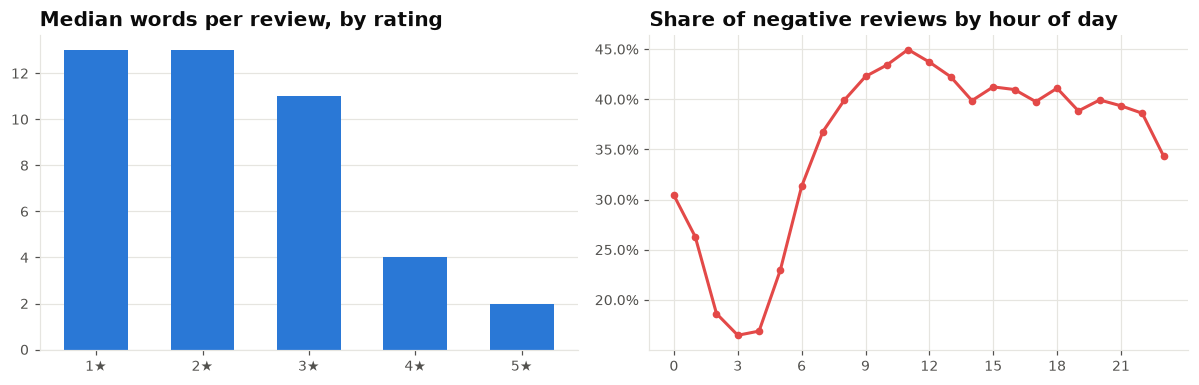

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
med_len = df[df.n_words > 0].groupby("score")["n_words"].median()
axes[0].bar(med_len.index.astype(str) + "★", med_len.values, color=BLUE, width=0.6)
axes[0].set_title("Median words per review, by rating"); axes[0].grid(axis="x", visible=False)

neg_hour = df.groupby("hour")["sentiment"].apply(lambda s: (s == "negative").mean())
axes[1].plot(neg_hour.index, neg_hour.values, marker="o", markersize=4, color=SENTIMENT_COLORS["negative"])
axes[1].set_title("Share of negative reviews by hour of day"); axes[1].set_xticks(range(0, 24, 3))
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
fig.tight_layout(); save(fig, "01_length_and_hour"); plt.show()

**Takeaway.** Negative reviews are much longer than positive ones ("Tốt" = "Good", "Ok") and carry far more detail about *specific problems* — which is why notebook 03 mines the text of negative reviews.
5★ reviews are often one or two words: there is little to learn from them, but they are easy to classify.

## 8. Summary for stakeholders
Exact figures are printed in each section above; the key points:
- Ratings are **strongly polarised** — the negative share is a more sensitive KPI than the average rating.
- The negative share **moves in waves tied to specific releases** → monitor per release, not just per month.
- Reply rate and time-to-reply are measurable customer-support levers.
- Negative reviews are long and information-rich → good input for topic analysis (notebook 03) and modelling (notebook 02).